# # Plotting with [XChart](https://knowm.org/open-source/xchart)
#
# [XChart](https://github.com/knowm/XChart) is a Java charting library, with few dependencies. It draws charts with
# Java 2D, so that we can get them as `BufferedImage`s, and show them in the notebook with almond's `Image` display.
# Other Java 2D-based libraries, like [JFreeChart](https://www.jfree.org/jfreechart), can be used the same way.

In [1]:
import $ivy.`org.knowm.xchart:xchart:4.0.4`

import org.knowm.xchart._
import org.knowm.xchart.internal.chartpart.IChart
import org.knowm.xchart.style.Styler

import scala.jdk.CollectionConverters._

// Renders a chart as a PNG image in the notebook
def show(chart: IChart) =
  Image.fromRenderedImage(BitmapEncoder.getBufferedImage(chart), Image.PNG)

import $ivy.$
import org.knowm.xchart._
import org.knowm.xchart.internal.chartpart.IChart
import org.knowm.xchart.style.Styler
import scala.jdk.CollectionConverters._
defined function show

# ## Line charts
#
# Charts are created with builders, then series are added to them. Most methods of the XChart API accept either
# Java arrays or Java lists.

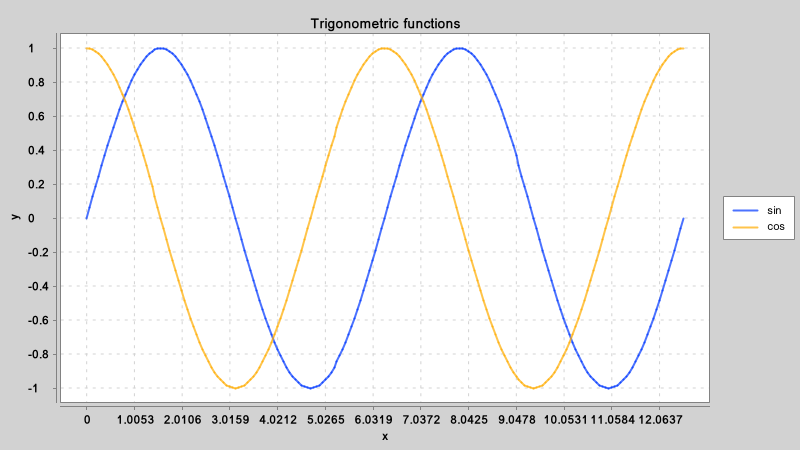

xs: Array[Double] = Array(
  0.0,
  0.06283185307179587,
  0.12566370614359174,
  0.18849555921538758,
  0.25132741228718347,
  0.3141592653589793,
  0.37699111843077515,
  0.43982297150257105,
  0.5026548245743669,
  0.5654866776461628,
  0.6283185307179586,
  0.6911503837897545,
  0.7539822368615503,
  0.8168140899333463,
  0.8796459430051421,
  0.9424777960769378,
  1.0053096491487339,
  1.0681415022205298,
  1.1309733552923256,
  1.1938052083641213,
  1.2566370614359172,
  1.3194689145077132,
  1.382300767579509,
  1.4451326206513047,
  1.5079644737231006,
  1.5707963267948966,
  1.6336281798666925,
  1.6964600329384882,
  1.7592918860102842,
  1.8221237390820801,
  1.8849555921538756,
  1.9477874452256716,
  2.0106192982974678,
  2.0734511513692637,
  2.1362830044410597,
  2.199114857512855,
  2.261946710584651,
  2.324778563656447,
...
lineChart: XYChart = org.knowm.xchart.XYChart@57493ed3
res2_2: Styler = org.knowm.xchart.style.XYStyler@12af593
res2_3: XYSeries = org.knowm.xchar

In [2]:
val xs = (0 to 200).map(_ * math.Pi / 50).toArray

val lineChart = new XYChartBuilder()
  .width(800)
  .height(450)
  .title("Trigonometric functions")
  .xAxisTitle("x")
  .yAxisTitle("y")
  .build()

lineChart.getStyler.setMarkerSize(0)
lineChart.addSeries("sin", xs, xs.map(math.sin))
lineChart.addSeries("cos", xs, xs.map(math.cos))

show(lineChart)

# ## Scatter charts
#
# The look of the charts is customized via their styler. Here, we draw points rather than lines, with
# the `GGPlot2` theme, that mimics the look of ggplot2 in R:

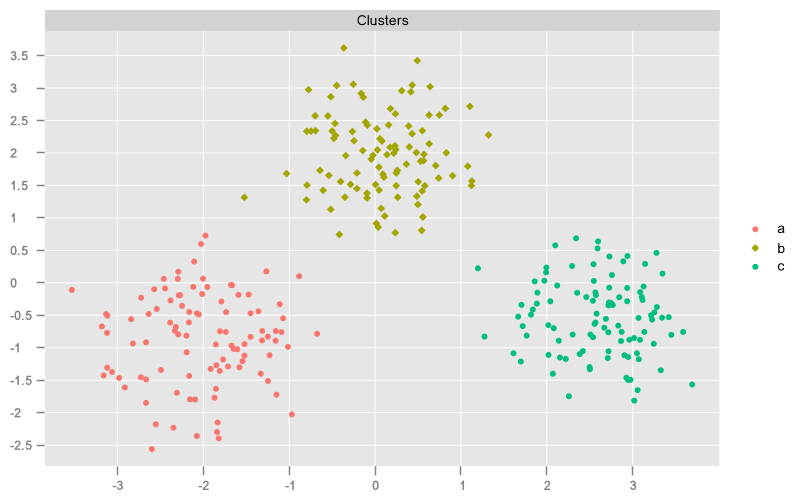

rng: scala.util.Random = scala.util.Random@6b7d2783
scatterChart: XYChart = org.knowm.xchart.XYChart@570bd666
res3_2: Styler = org.knowm.xchart.style.XYStyler@773ed373

In [3]:
val rng = new scala.util.Random(42)

val scatterChart = new XYChartBuilder()
  .width(800)
  .height(500)
  .title("Clusters")
  .theme(Styler.ChartTheme.GGPlot2)
  .build()

scatterChart.getStyler
  .setDefaultSeriesRenderStyle(XYSeries.XYSeriesRenderStyle.Scatter)
  .setMarkerSize(6)

for ((name, (cx, cy)) <- Seq("a" -> (-2.0, -1.0), "b" -> (0.0, 2.0), "c" -> (2.5, -0.5))) {
  val x = Array.fill(100)(cx + 0.6 * rng.nextGaussian())
  val y = Array.fill(100)(cy + 0.6 * rng.nextGaussian())
  scatterChart.addSeries(name, x, y)
}

show(scatterChart)

# ## Bar charts

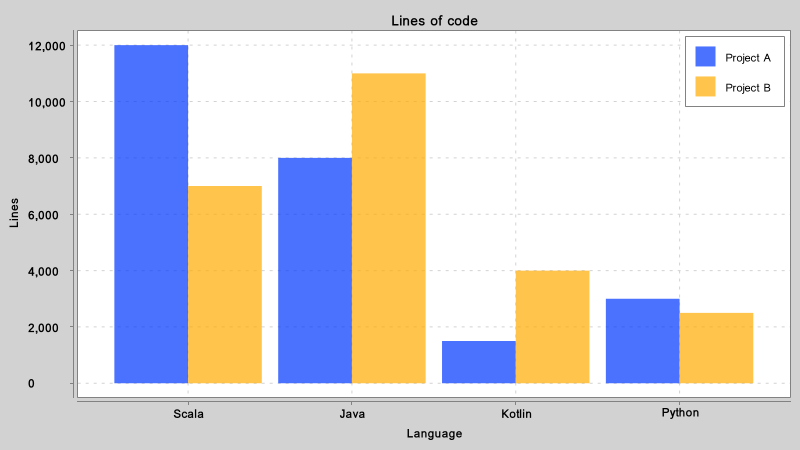

languages: Seq[String] = List("Scala", "Java", "Kotlin", "Python")
barChart: CategoryChart = org.knowm.xchart.CategoryChart@43c10dee
res4_2: Styler = org.knowm.xchart.style.CategoryStyler@129f470c
res4_3: CategorySeries = org.knowm.xchart.CategorySeries@2467f187
res4_4: CategorySeries = org.knowm.xchart.CategorySeries@78a113aa

In [4]:
val languages = Seq("Scala", "Java", "Kotlin", "Python")

val barChart = new CategoryChartBuilder()
  .width(800)
  .height(450)
  .title("Lines of code")
  .xAxisTitle("Language")
  .yAxisTitle("Lines")
  .build()

barChart.getStyler.setLegendPosition(Styler.LegendPosition.InsideNE)

barChart.addSeries(
  "Project A",
  languages.asJava,
  Seq[Number](12000, 8000, 1500, 3000).asJava
)
barChart.addSeries(
  "Project B",
  languages.asJava,
  Seq[Number](7000, 11000, 4000, 2500).asJava
)

show(barChart)

# ## Histograms
#
# The `Histogram` class bins values, that a category chart can draw:

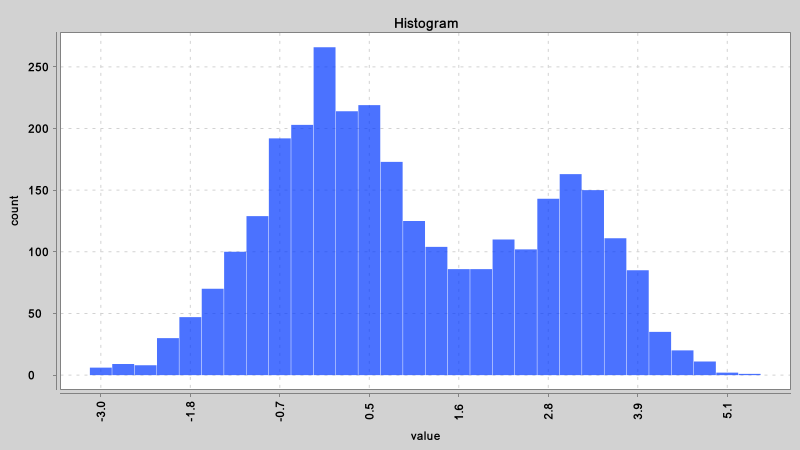

samples: Seq[Double] = List(
  -0.31345109161065926,
  0.6888181847006613,
  0.5612615114298306,
  -0.7192496970606022,
  -0.23883628989818786,
  -0.8245600778410896,
  -0.14678636778810134,
  0.6171101997247541,
  1.487562859731773,
  1.1695780390240165,
  2.746488178488735,
  -0.409778806805365,
  0.4116785188193896,
  -1.302213259977852,
  0.39003484312803977,
  0.8058092139513117,
  0.9063920023065685,
  -1.6748417828946516,
  0.2856680423450676,
  0.41813221760139374,
  0.3957855809267267,
  -0.3211224661264767,
  0.2694449274462255,
  -0.22607792778044114,
  0.6662774494836935,
  -0.7736184935673468,
  -0.6253801743264935,
  -0.3018474878790466,
  -0.3340805317263219,
  1.3438356681498298,
  -0.6179037079858032,
  -1.1147496913709418,
  0.44564307678266174,
  0.7541264342573287,
  -0.4158736094055973,
  -0.6689521846321478,
  -0.8638925037400046,
  1.1517668203954323,
...
histogram: Histogram = org.knowm.xchart.Histogram@67edc305
histogramChart: CategoryChart = org.knowm.xchart.C

In [5]:
val samples = Seq.fill(2000)(rng.nextGaussian()) ++ Seq.fill(1000)(3 + 0.7 * rng.nextGaussian())
val histogram = new Histogram(samples.map(Double.box).asJava, 30)

val histogramChart = new CategoryChartBuilder()
  .width(800)
  .height(450)
  .title("Histogram")
  .xAxisTitle("value")
  .yAxisTitle("count")
  .build()

val histogramStyler = histogramChart.getStyler
histogramStyler.setLegendVisible(false)
histogramStyler.setXAxisDecimalPattern("0.0")
histogramStyler.setXAxisLabelRotation(90)
histogramStyler.setAvailableSpaceFill(0.98)

histogramChart.addSeries("samples", histogram.getxAxisData, histogram.getyAxisData)

show(histogramChart)

# ## Pie charts

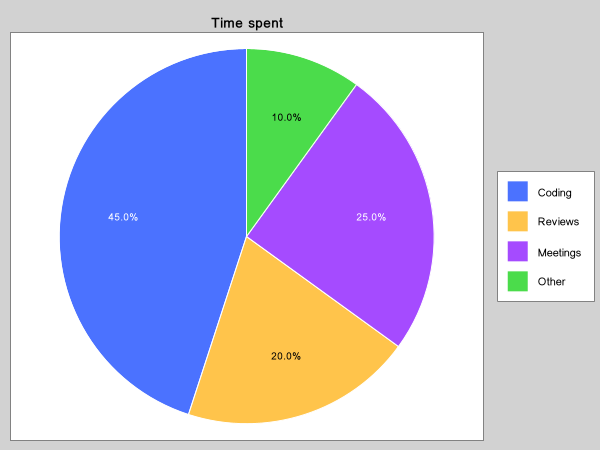

pieChart: PieChart = org.knowm.xchart.PieChart@4445c294

In [6]:
val pieChart = new PieChartBuilder()
  .width(600)
  .height(450)
  .title("Time spent")
  .build()

for ((name, share) <- Seq("Coding" -> 45, "Reviews" -> 20, "Meetings" -> 25, "Other" -> 10))
  pieChart.addSeries(name, share)

show(pieChart)

# ## Box plots

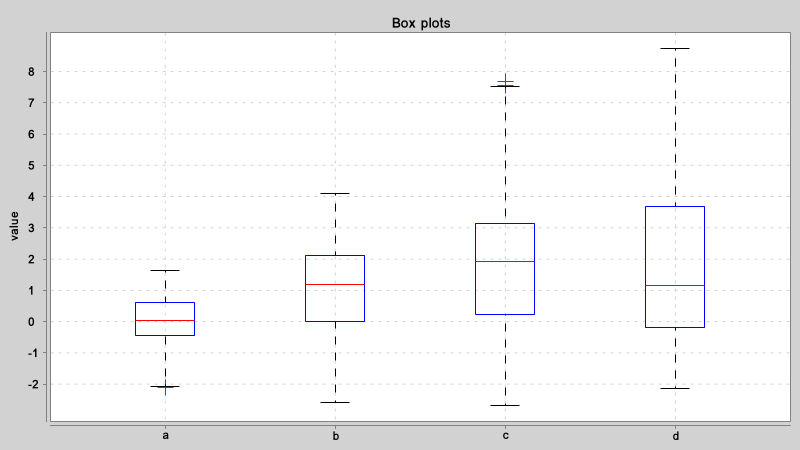

boxChart: BoxChart = org.knowm.xchart.BoxChart@5284a458

In [7]:
val boxChart = new BoxChartBuilder()
  .width(800)
  .height(450)
  .title("Box plots")
  .yAxisTitle("value")
  .build()

for (group <- Seq("a", "b", "c", "d")) {
  val shift = group.head - 'a'
  boxChart.addSeries(group, Array.fill(50)(shift + rng.nextGaussian() * (1 + shift / 2.0)))
}

show(boxChart)

# ## Vector output
#
# `ChartEncoder` writes charts as SVG, EPS or PDF too. For SVG, it relies on the
# [VectorGraphics2D](https://github.com/eseifert/vectorgraphics2d) library, that we need to add:

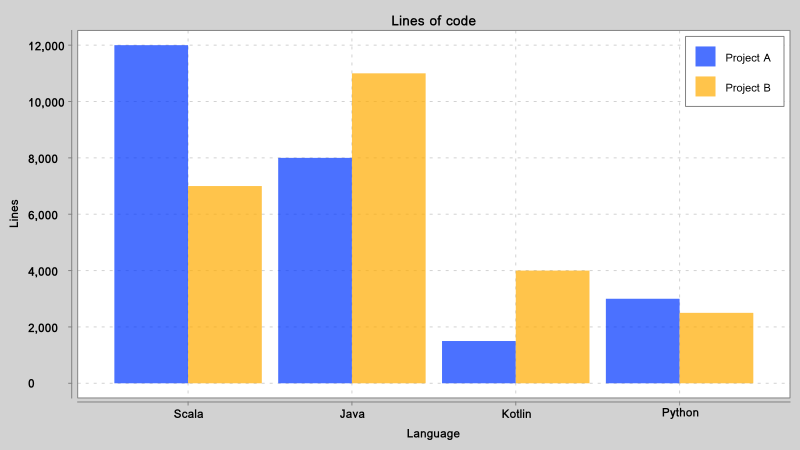

import $ivy.$

In [8]:
import $ivy.`de.erichseifert.vectorgraphics2d:VectorGraphics2D:0.13`

Svg(new String(ChartEncoder.getBytes(barChart, "svg"), "UTF-8"))

# See the [XChart examples](https://knowm.org/open-source/xchart/xchart-example-code) for more chart types
# (area charts, bubble charts, heat maps, dial charts, radar charts, OHLC charts…) and styling options.